In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

# Load dataset
iris = pd.read_csv(r"C:\Users\user\Downloads\Iris.csv")

# Independent variables
X = iris[[
    "SepalLengthCm",
    "SepalWidthCm",
    "PetalLengthCm",
    "PetalWidthCm"
]]

# Dependent variable
y = iris["Species"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=21,
    stratify=y
)

# Scale the features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Train KNN model
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

# Make predictions
y_pred = knn.predict(X_test)

# Evaluate model
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Predictions:", y_pred[:5])

Accuracy: 0.9333333333333333
Predictions: ['Iris-virginica' 'Iris-versicolor' 'Iris-virginica' 'Iris-virginica'
 'Iris-versicolor']


In [3]:
train_accuracies={}
test_accuracies={}
neighbors=np.arange(1,25)
for neighbor in neighbors:
    knn=KNeighborsClassifier(n_neighbors=neighbor)
    knn.fit(X_train, y_train)
    train_accuracies[neighbor]=knn.score(X_train, y_train)
    test_accuracies[neighbor]=knn.score(X_test, y_test)
print(train_accuracies)
print(test_accuracies)

{np.int64(1): 1.0, np.int64(2): 0.9619047619047619, np.int64(3): 0.9619047619047619, np.int64(4): 0.9619047619047619, np.int64(5): 0.9619047619047619, np.int64(6): 0.9619047619047619, np.int64(7): 0.9619047619047619, np.int64(8): 0.9619047619047619, np.int64(9): 0.9714285714285714, np.int64(10): 0.9619047619047619, np.int64(11): 0.9523809523809523, np.int64(12): 0.9428571428571428, np.int64(13): 0.9428571428571428, np.int64(14): 0.9333333333333333, np.int64(15): 0.9428571428571428, np.int64(16): 0.9523809523809523, np.int64(17): 0.9428571428571428, np.int64(18): 0.9523809523809523, np.int64(19): 0.9428571428571428, np.int64(20): 0.9428571428571428, np.int64(21): 0.9428571428571428, np.int64(22): 0.9428571428571428, np.int64(23): 0.9428571428571428, np.int64(24): 0.9333333333333333}
{np.int64(1): 0.9555555555555556, np.int64(2): 0.9333333333333333, np.int64(3): 0.9777777777777777, np.int64(4): 0.9333333333333333, np.int64(5): 0.9333333333333333, np.int64(6): 0.9333333333333333, np.int64

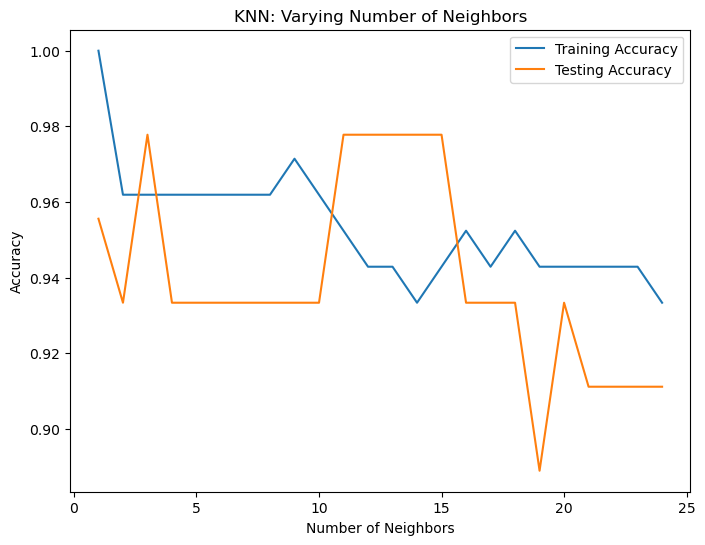

In [4]:
plt.figure(figsize=(8, 6)) 
plt.title("KNN: Varying Number of Neighbors") 
plt.plot(neighbors, train_accuracies.values(), label="Training Accuracy") 
plt.plot(neighbors, test_accuracies.values(), label="Testing Accuracy") 
plt.legend() 
plt.xlabel("Number of Neighbors") 
plt.ylabel("Accuracy") 
plt.show()

In [47]:
diabetes_df=pd.read_csv(r"C:\Users\user\Downloads\diabetes_prediction_dataset.csv\diabetes_prediction_dataset.csv")
print(diabetes_df.head(7))
print(diabetes_df.columns.tolist())
print(diabetes_df["smoking_history"].unique())

   gender   age  hypertension  heart_disease smoking_history    bmi  \
0  Female  80.0             0              1           never  25.19   
1  Female  54.0             0              0         No Info  27.32   
2    Male  28.0             0              0           never  27.32   
3  Female  36.0             0              0         current  23.45   
4    Male  76.0             1              1         current  20.14   
5  Female  20.0             0              0           never  27.32   
6  Female  44.0             0              0           never  19.31   

   HbA1c_level  blood_glucose_level  diabetes  
0          6.6                  140         0  
1          6.6                   80         0  
2          5.7                  158         0  
3          5.0                  155         0  
4          4.8                  155         0  
5          6.6                   85         0  
6          6.5                  200         1  
['gender', 'age', 'hypertension', 'heart_diseas

In [49]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

diabetes_df["gender"] = le.fit_transform(diabetes_df["gender"])#label encoding

diabetes_df = pd.get_dummies(
    diabetes_df,
    columns=["smoking_history"],
    dtype=int
)#one_hot encoding

In [ ]:
X=diabetes_df.drop(["blood_glucose_level"],axis=1).values
y=diabetes_df["blood_glucose_level"].values  

In [42]:
print(type(X), type(y))

<class 'numpy.ndarray'> <class 'numpy.ndarray'>


In [40]:
X_bmi=diabetes_df["bmi"].values
print(y.shape,X_bmi.shape) #for feature column it is necessary that it must be in 2D


(100000,) (100000,)


In [26]:
#converting X_bmi into 2D 
X_bmi=X_bmi.reshape(-1,1) #-1 means all rows and 1 means 1 column
print(X_bmi.shape)

(100000, 1)


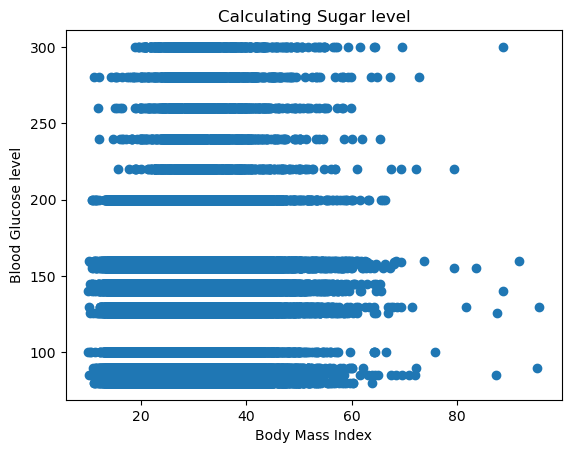

In [27]:
plt.scatter(X_bmi,y)
plt.xlabel("Body Mass Index")
plt.ylabel("Blood Glucose level")
plt.title("Calculating Sugar level")
plt.show()

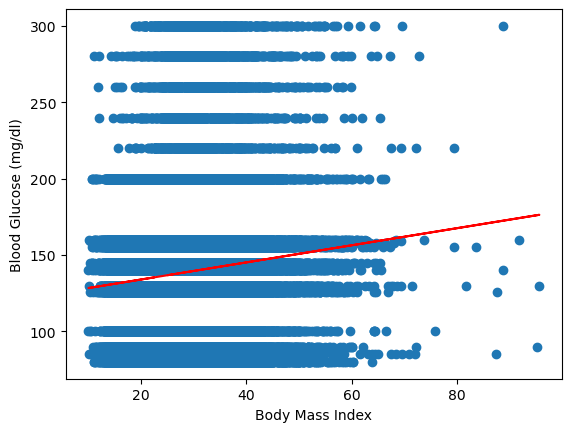

In [28]:
#Regression using a single feature
from sklearn.linear_model import LinearRegression
reg=LinearRegression()
reg.fit(X_bmi,y)
predictions=reg.predict(X_bmi)
plt.scatter(X_bmi,y)
plt.plot(X_bmi,predictions,color="red") #This graph can draw linear regression line?
plt.ylabel("Blood Glucose (mg/dl)") 
plt.xlabel("Body Mass Index") 
plt.show()

In [54]:
#Regression using all features
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
X_train,X_test, y_train , y_test=train_test_split(X,y ,random_state=24,test_size=0.3)
reg_all=LinearRegression()
reg_all.fit(X_train,y_train)
predictions=reg_all.predict(X_test)
print(predictions[:5])
reg_all.score(X_test, y_test)

[133.00376471 132.79647997 133.33262673 133.01017668 133.54914844]


0.17676906238914747

In [57]:
#RMSE in scikit-learn
from sklearn.metrics import root_mean_squared_error 
root_mean_squared_error(y_test, predictions)

37.027093636023636